In [44]:
import numpy as np
import pandas as pd
import json

# Librerías de terceros
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay
from sklearn.metrics import precision_score, recall_score, f1_score


In [38]:
df = pd.read_csv('../datasets/df_procesado.csv')


In [39]:
# Separación de los datos en entrenamiento (80%) y validación (20%):

X = df.drop('loan_status', axis=1)
y = df['loan_status']

X_train, X_val, y_train, y_val = train_test_split(
       X, y, test_size=0.2, stratify=y, random_state=56
   )


In [56]:
print("Distribución de la variable respuesta en los datos de entrenamiento:")
print(y_train.value_counts(normalize=True))
print("\n")
print("Distribución de la variable respuesta en los datos de validación:")
print(y_val.value_counts(normalize=True))

Distribución de la variable respuesta en los datos de entrenamiento:
loan_status
0    0.766977
1    0.233023
Name: proportion, dtype: float64


Distribución de la variable respuesta en los datos de validación:
loan_status
0    0.766977
1    0.233023
Name: proportion, dtype: float64


In [18]:
# Selecciona GPU si está disponible, de lo contrario usa CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Muestra el dispositivo que se está utilizando
print(f"Usando: {device}")

Usando: cpu


In [22]:

# Convertir a tensores y crear DataLoaders
X_train_t = torch.tensor(X_train.to_numpy(), dtype=torch.float32).to(device)
X_val_t  = torch.tensor(X_val.to_numpy(),  dtype=torch.float32).to(device)
y_train_t = torch.tensor(y_train.to_numpy(), dtype=torch.float32).to(device)
y_val_t  = torch.tensor(y_val.to_numpy(),  dtype=torch.float32).to(device)

train_ds = TensorDataset(X_train_t, y_train_t)
test_ds  = TensorDataset(X_val_t,  y_val_t)

train_loader = DataLoader(train_ds, batch_size=512, shuffle=True)
test_loader  = DataLoader(test_ds,  batch_size=512, shuffle=False)

print(f"Batches en train: {len(train_loader)}")

Batches en train: 302


In [24]:
# Definir arquitectura de la red neuronal
# Estructura: Input → 128 → 64 → 32 → 1
# Dropout para regularización, BatchNorm para estabilidad

class CreditRiskNN(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.network = nn.Sequential(
            # Capa 1
            nn.Linear(input_dim, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.2),
            # Capa 2
            nn.Linear(64, 32),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.Dropout(0.2),
            # Capa 3
            nn.Linear(32, 16),
            nn.BatchNorm1d(16),
            nn.ReLU(),
            #nn.Dropout(0.2),
            # Salida — probabilidad de default
            nn.Linear(16, 1),
            #nn.Sigmoid()
        )

    def forward(self, x):
        return self.network(x).squeeze(1)

model = CreditRiskNN(input_dim=X_train.shape[1]).to(device)
print(model)
print(f"\nParámetros totales: {sum(p.numel() for p in model.parameters()):,}")

CreditRiskNN(
  (network): Sequential(
    (0): Linear(in_features=44, out_features=64, bias=True)
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=64, out_features=32, bias=True)
    (5): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.2, inplace=False)
    (8): Linear(in_features=32, out_features=16, bias=True)
    (9): BatchNorm1d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): Linear(in_features=16, out_features=1, bias=True)
  )
)

Parámetros totales: 5,729


In [40]:
y_train

91756     0
184211    1
157489    0
59567     0
12783     1
         ..
47946     1
184388    1
81449     0
102756    0
42999     0
Name: loan_status, Length: 154440, dtype: int64

In [41]:
# Configurar entrenamiento
# BCELoss con pos_weight para manejar desbalance de clases

# Peso para clase positiva (default) según desbalance
n_neg = (y_train == 0).sum()
n_pos = (y_train == 1).sum()
pos_weight = torch.tensor([n_neg / n_pos], dtype=torch.float32).to(device)
print(f"pos_weight: {pos_weight.item():.2f}  (negativos/positivos)")

criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="max", patience=3, factor=0.5
)

pos_weight: 3.29  (negativos/positivos)


In [43]:

# Loop de entrenamiento

EPOCHS = 30
history = {"train_loss": [], "val_auc": []}

for epoch in range(1, EPOCHS + 1):
    # ── Entrenamiento ──────────────────────────────────────────
    model.train()
    total_loss = 0
    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()
        preds = model(X_batch)
        loss  = criterion(preds, y_batch)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    avg_loss = total_loss / len(train_loader)

    # ── Validación ─────────────────────────────────────────────
    model.eval()
    with torch.no_grad():
        y_prob_val = model(X_val_t).cpu().numpy()

    val_auc = roc_auc_score(y_val, y_prob_val)
    scheduler.step(val_auc)
    print(f"Epoch {epoch} | LR: {optimizer.param_groups[0]['lr']}")

    history["train_loss"].append(avg_loss)
    history["val_auc"].append(val_auc)

    if epoch % 5 == 0 or epoch == 1:
        print(f"Epoch {epoch:02d}/{EPOCHS} | Loss: {avg_loss:.4f} | AUC: {val_auc:.4f}")

y_prob = y_prob_val

Epoch 1 | LR: 0.001
Epoch 01/30 | Loss: -25.3032 | AUC: 0.6880
Epoch 2 | LR: 0.001
Epoch 3 | LR: 0.001
Epoch 4 | LR: 0.001
Epoch 5 | LR: 0.0005
Epoch 05/30 | Loss: -285.0607 | AUC: 0.6826
Epoch 6 | LR: 0.0005
Epoch 7 | LR: 0.0005
Epoch 8 | LR: 0.0005
Epoch 9 | LR: 0.00025
Epoch 10 | LR: 0.00025
Epoch 10/30 | Loss: -556.1404 | AUC: 0.6877
Epoch 11 | LR: 0.00025
Epoch 12 | LR: 0.00025
Epoch 13 | LR: 0.00025
Epoch 14 | LR: 0.00025
Epoch 15 | LR: 0.00025
Epoch 15/30 | Loss: -693.6952 | AUC: 0.6883
Epoch 16 | LR: 0.00025
Epoch 17 | LR: 0.00025
Epoch 18 | LR: 0.00025
Epoch 19 | LR: 0.00025
Epoch 20 | LR: 0.00025
Epoch 20/30 | Loss: -840.3971 | AUC: 0.6889
Epoch 21 | LR: 0.00025
Epoch 22 | LR: 0.00025
Epoch 23 | LR: 0.00025
Epoch 24 | LR: 0.00025
Epoch 25 | LR: 0.000125
Epoch 25/30 | Loss: -998.3541 | AUC: 0.6898
Epoch 26 | LR: 0.000125
Epoch 27 | LR: 0.000125
Epoch 28 | LR: 0.000125
Epoch 29 | LR: 6.25e-05
Epoch 30 | LR: 6.25e-05
Epoch 30/30 | Loss: -1086.3187 | AUC: 0.6901


In [47]:
thresholds = np.linspace(0.01, 0.9, 100)

results = []

for t in thresholds:
    y_pred = (y_prob_val > t).astype(int)
    
    precision = precision_score(y_val, y_pred, zero_division=0)
    recall = recall_score(y_val, y_pred)
    f1 = f1_score(y_val, y_pred)
    
    results.append((t, precision, recall, f1))

results = np.array(results)

In [48]:
# encontrar mejor threshold según F1
best_idx = np.argmax(results[:, 3])
best_threshold = results[best_idx, 0]
best_precision = results[best_idx, 1]
best_recall = results[best_idx, 2]
best_f1 = results[best_idx, 3]  
print(f"Mejor threshold: {best_threshold:.2f} | Precision: {best_precision:.4f} | Recall: {best_recall:.4f} | F1: {best_f1:.4f}")
    

Mejor threshold: 0.01 | Precision: 0.0000 | Recall: 0.0000 | F1: 0.0000


In [49]:
# Después del loop de entrenamiento
model.eval()
with torch.no_grad():
    logits = model(X_val_t)
    y_prob_val = torch.sigmoid(logits).cpu().numpy().flatten()
    y_pred = (y_prob_val > best_threshold).astype(int)

classification_report(y_val, y_pred)

'              precision    recall  f1-score   support\n\n           0       0.83      0.78      0.81     29613\n           1       0.40      0.48      0.44      8997\n\n    accuracy                           0.71     38610\n   macro avg       0.62      0.63      0.62     38610\nweighted avg       0.73      0.71      0.72     38610\n'

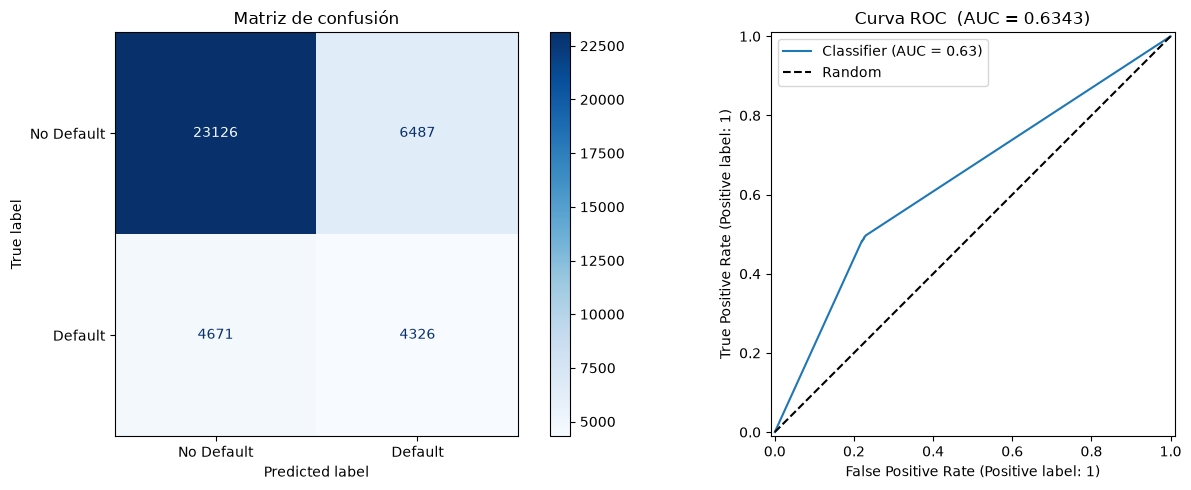

In [51]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Matriz de confusión
ConfusionMatrixDisplay.from_predictions(
    y_val, y_pred,
    display_labels=["No Default", "Default"],
    cmap="Blues",
    ax=axes[0]
)
axes[0].set_title("Matriz de confusión")

# Curva ROC
RocCurveDisplay.from_predictions(y_val, y_prob_val, ax=axes[1])
axes[1].set_title(f"Curva ROC  (AUC = {roc_auc_score(y_val, y_prob_val):.4f})")
axes[1].plot([0, 1], [0, 1], "k--", label="Random")
axes[1].legend()

plt.tight_layout()
plt.show()


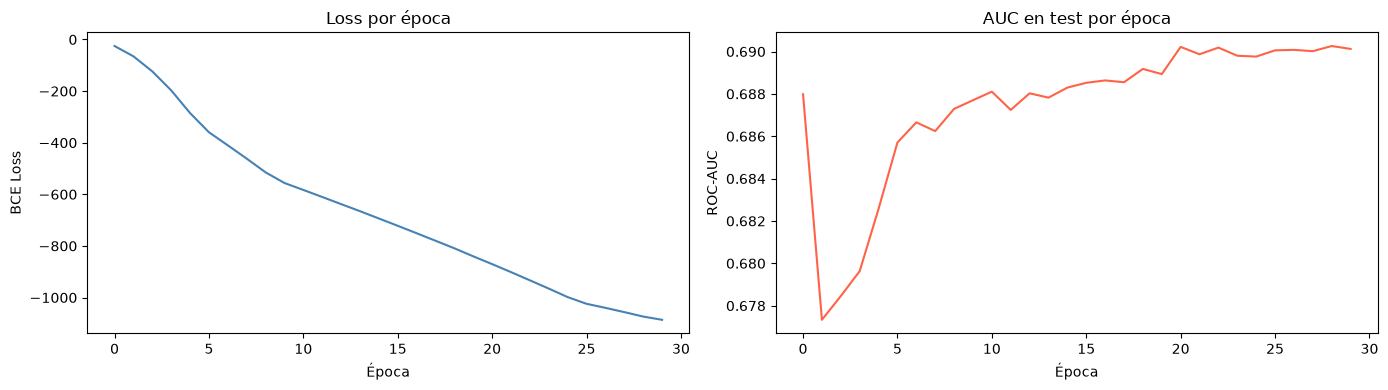

In [52]:

# Curvas de entrenamiento
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(history["train_loss"], color="steelblue")
axes[0].set_title("Loss por época")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("BCE Loss")

axes[1].plot(history["val_auc"], color="tomato")
axes[1].set_title("AUC en test por época")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("ROC-AUC")

plt.tight_layout()
plt.show()

In [ ]:
model.eval()
with torch.no_grad():
    y_prob = model(X_val_t).cpu().numpy()

y_pred = (y_prob >= 0.5).astype(int)

print("── Classification Report ──────────────────────────────────")
print(classification_report(y_val, y_pred,
                             target_names=["No Default", "Default"]))
print(f"ROC-AUC: {roc_auc_score(y_val, y_prob):.4f}")

In [54]:

# import pickle

torch.save(model.state_dict(), "../weights/modelo_clasificador.pth")
# pickle.dump(scaler, open("scaler.pkl", "wb"))

print("Modelo guardado en modelo_clasificador.pth")
print("Scaler guardado en scaler.pkl")

Modelo guardado en modelo_clasificador.pth
Scaler guardado en scaler.pkl
